# Homework 1 – Your corpus: duplicates & completeness

_MIR & ML for Audio · TU Berlin · WiSe 2026/27_

Please fill out:
| | |
|---|---|
| **Name** | Hallvard Jensen |
| **Student ID** | 0549158 |
| **Corpus (genre)** | Nu Disco/Disco |

**Submission:** work in this notebook – code, figures and text answers all stay here.

Before uploading: **Restart Kernel & Run All**, check that every output is shown, then upload this `.ipynb` file along with the graphics/plots.


## Tasks

1. Choose a practice corpus (Beatport charts 2013–2023 of one EDMC genre) from 19 genres – as individual as possible:
   afro house · breaks / breakbeat / UK bass · dance / electro-pop · deep house · drum'n'bass · dubstep · electronica · hard dance / hardcore · house · indie dance · melodic house / techno · minimal / deep tech · nu disco / disco · psytrance · tech house · techno · trance (main floor) · trap / wave · UK garage / bassline
2. Download your corpus (CSV and Top 100 preview MP3s per year): https://tubcloud.tu-berlin.de/s/pgpibnbNfSF5jnM
3. Create a duplicate-free preview folder for all years (`previews/`).
4. Based on the CSV file, create statistics and visualisations of the **completeness of metadata and audio data per chart year** for your corpus.


---

## Setup

Expected project structure (relative to this notebook):

```
<course folder>/
├── HW01_corpus_completeness.ipynb
├── data/
│   └── <your-genre>/
│       ├── <genre>.csv
│       ├── previews/          ← task 3
│       └── 2013/top100/ … 2023/top100/
└── output/                    ← figures & tables
```


In [626]:
# import standard packages you'll need

import sys
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print(sys.executable)
print("pandas", pd.__version__)

# ─ add your own additional imports here:
from datetime import datetime

/home/hallvard/miniforge3/envs/mirml/bin/python
pandas 3.1.0


In [ ]:
# ── CONFIG ───────────────────────────────────────────────────────────────
CORPUS_DIR = Path("data") / "nu-disco-disco"  # ← name of your corpus folder
# ─────────────────────────────────────────────────────────────────────────
PREVIEW_DIR = CORPUS_DIR / "previews"
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

assert (
    CORPUS_DIR.is_dir()
), f"Not found: {CORPUS_DIR.resolve()} → check CORPUS_DIR"
CHART_CSV = next(CORPUS_DIR.glob("*.csv"))
print(CHART_CSV)

data/nu-disco-disco/Nu_Disco_Disco.csv


---

## Tasks 1 + 2 · Corpus

Fill in your genre in the table at the top and set `CORPUS_DIR` in the CONFIG cell.

Please make sure that you choose an unclaimed genre, there should be one for each!


---

## Task 3 · Duplicate-free `previews/` folder


In [ ]:
# Task 3: create previews/
all_mp3s = sorted(CORPUS_DIR.glob("*/top100/*.mp3"))
ids = pd.Series(all_mp3s)

PREVIEW_DIR.mkdir(exist_ok=True)
for song_id in ids.tolist():
    dst = PREVIEW_DIR / song_id.name
    if not dst.exists():
        shutil.copy2(song_id, dst)

In [629]:
# Task 3: check your result
preview_ids = pd.Series([p.stem for p in PREVIEW_DIR.glob("*.mp3")])
all_ids = pd.Series([p.stem for p in all_mp3s])
print(f"Total ids found: {all_ids.count()}")
print(f"Unique ids found: {all_ids.nunique()}")
print(f"Duplicates: {all_ids.count()-all_ids.nunique()}")
print(f"Total ids in preview/: {preview_ids.count()}")
print(f"Unique ids in preview/: {preview_ids.nunique()}")

Total ids found: 464
Unique ids found: 315
Duplicates: 149
Total ids in preview/: 315
Unique ids in preview/: 315


### Answer 3

_Briefly describe your approach and your result (numbers)._

In the first code block I collect all found mp3 paths, create the previews directory, and iterate over all found paths and copy them to previews. Uniqueness check is done simply by checking if the filename already exists in previews/. This is necessary, since we need the complete relative path to the original mp3 file to be able to copy it to previews/.

In the checking code block I make two series with only ids for the contents of previews/ and all ids found in the data set. Then I compare the found ids, how many uniques and duplicates with what is found in previews/. We see here that 464 ids were found, with 149 duplicates, which makes 315 uniques. In preview we have 315 entries and all 315 are unique, which means all unique ids have been copied.


---

## Task 4 · Completeness per chart year

### 4.1 Load & inspect the chart table


In [ ]:
# Task 4.1: load & inspect
charts = pd.read_csv(CHART_CSV)
print(charts.shape)
print(charts.head().to_string())
charts.info()

(3813, 14)
   year  rank  points  days_charted  beatport_track_id                        title                                       mix                                 artist         label  duration_ms subgenre          isrc    bpm release_date
0  2019     1   11313           116           12210204                      Emotion                              Extended Mix                   Purple Disco Machine    Club Sweat     369674.0      NaN  AUDCB1701419  122.0   2019-07-19
1  2019     2   11107           116           12360939             Express Yourself                              Original Mix                             Mark Lower  Salted Music     379000.0      NaN  USATE1916201  122.0   2019-08-02
2  2019     3   10736           116           12310558                          NaN                                       NaN                                    NaN           NaN          NaN      NaN           NaN    NaN          NaN
3  2019     4   10490           116           124

### 4.2 Completeness of metadata per chart year


In [738]:
# Task 4.2: statistics
clean = charts.copy()


def print_mask(
    text: str, df: pd.DataFrame, mask: pd.DataFrame | pd.Series
) -> None:
    if isinstance(mask, pd.Series):
        mask = mask.to_frame(mask.name)

    per_year = mask.groupby(df.year).sum()
    per_year = per_year.loc[:, per_year.sum() > 0]
    print(
        f"{text}:{f"\n{per_year.to_string()}\n" if not per_year.empty else " 0"}"
    )


# Replace all empty and whitespace strings with nan
str_cols = clean.select_dtypes(include="str").columns
blank_mask = clean[str_cols].apply(
    lambda col: col.str.fullmatch(r"\s*", na=False)
)
clean[str_cols] = clean[str_cols].mask(blank_mask)
print_mask("Empty or whitespace strings removed", clean, blank_mask)

placeholders = ["unknown", "-", "."]
placeholder_mask = clean[str_cols].apply(
    lambda col: col.str.strip().str.lower().isin(placeholders)
)
clean[str_cols] = clean[str_cols].mask(placeholder_mask)
print_mask("Placeholder strings removed", clean, placeholder_mask)

num_cols = clean.select_dtypes(include="number").columns

# No number columns should be negative
neg_mask = clean[num_cols] < 0
clean[num_cols] = clean[num_cols].mask(neg_mask)
print_mask("Negative numbers removed", clean, neg_mask)

# No number columns, except "points", should be 0
nzero_cols = num_cols.drop("points")
zero_mask = clean[nzero_cols] == 0
clean[nzero_cols] = clean[nzero_cols].mask(zero_mask)
print_mask("Zero values removed", clean, zero_mask)

# Remove BPM outside a sensible range
bpm_mask = (clean.bpm < 50) | (clean.bpm > 250)
clean.bpm = clean.bpm.mask(bpm_mask)
print_mask("BPMs outside 50-250 removed", clean, bpm_mask)

# Release date should be an actual date
dates = pd.to_datetime(clean.release_date, errors="coerce")
invalid_dates = dates.isna() & clean.release_date.notna()
date_outside_range = (dates < "1970-01-01") | (dates > "2023-12-12")
clean.release_date = dates.mask(invalid_dates | date_outside_range)

print_mask("Invalid dates removed", clean, invalid_dates)
print_mask("Dates outside range", clean, date_outside_range)

dupes = clean.duplicated(["year", "beatport_track_id"]).rename("duplicate_ids")
print_mask("Duplicated beatport IDs", clean, dupes)

print("Rows with NaN:")
print(clean.isna().groupby(clean.year).sum().to_string())

print("Percentage of rows with NaN:")
print((clean.isna().groupby(clean.year).mean() * 100).round(2).to_string())

Empty or whitespace strings removed: 0
Placeholder strings removed: 0
Negative numbers removed: 0
Zero values removed:
      bpm
year     
2019    2
2020    4
2021    0
2022    0
2023    0

BPMs outside 50-250 removed: 0
Invalid dates removed: 0
Dates outside range: 0
Duplicated beatport IDs: 0
Rows with NaN:
      year  rank  points  days_charted  beatport_track_id  title  mix  artist  label  duration_ms  subgenre  isrc  bpm  release_date
year                                                                                                                                
2019     0     0       0             0                  0     50   50      50     50           50       385    53   52            50
2020     0     0       0             0                  0     62   62      62     62           62       929    71   66            62
2021     0     0       0             0                  0     35   35      35     35           35       853    35   35            35
2022     0     0       0

In [739]:
# Extras

print("\nNumber of unique tracks per year:")
unique_tracks = clean.groupby("year").beatport_track_id.nunique()
print(unique_tracks.to_string())

print(
    f"\nThere are only {charts.subgenre.notna().sum()} tracks with non-null subgenres."
)
print("The only found subgenres are: ")
print(clean.dropna().groupby("year").subgenre.unique().to_string())

unusual_bpm = clean.bpm.notna() & ~charts.bpm.between(50, 200)
print("\nTracks with unusual BPMs per year:")
print(
    clean.loc[unusual_bpm]
    .groupby(["year", "bpm"])
    .title.apply(list)
    .to_string()
)

# Convert string format string to datetime
clean.release_date = pd.to_datetime(clean.release_date)

date = datetime(year=2000, month=1, day=1)
date_mask = clean.release_date < date

print(f"\nNumber of charting tracks with release date before {date.year}:")
print(clean.loc[date_mask].groupby("year").size().to_string())

duration_mask = ~clean.duration_ms.between(1000 * 60 * 2, 1000 * 60 * 8)
print(f"\nDuration less than 2 minutes or more than 8 minutes:")
print(
    clean.dropna()
    .loc[duration_mask, ["year", "title", "duration_ms"]]
    .groupby(["year", "duration_ms"])
    .title.apply(list)
    .to_string()
)


Number of unique tracks per year:
year
2019    393
2020    936
2021    873
2022    819
2023    792

There are only 52 tracks with non-null subgenres.
The only found subgenres are: 
year
2019    [Dark Disco, Funk / Soul]
2020    [Funk / Soul, Dark Disco]
2021         [Italo, Funk / Soul]
2022         [Funk / Soul, Italo]
2023         [Funk / Soul, Italo]

Tracks with unusual BPMs per year:
year  bpm  
2022  240.0    [The Night, She Got Everything]

Number of charting tracks with release date before 2000:
year
2019    2
2022    1
2023    2

Duration less than 2 minutes or more than 8 minutes:
year  duration_ms
2019  511315.0        [Another Man]
2020  633262.0       [Back To Life]


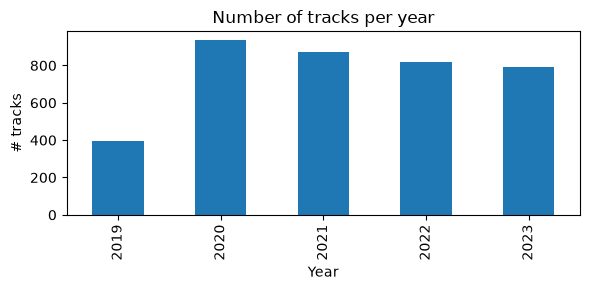

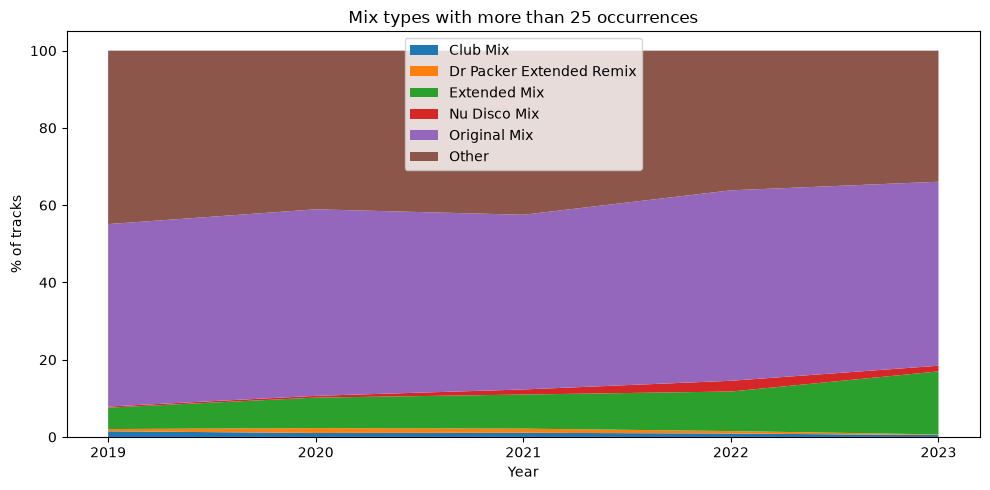

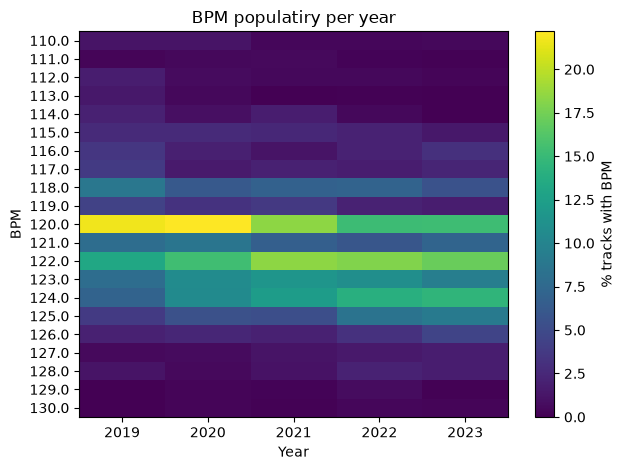

In [ ]:
# Task 4.2: visualisation
ax = unique_tracks.plot(figsize=(6, 3), kind="bar")
ax.set(xlabel="Year", ylabel="# tracks", title="Unique tracks per year")
ax.figure.tight_layout()
ax.figure.savefig(OUTPUT_DIR / "tracks-per-year.png", bbox_inches="tight")
plt.show()

mix_copy = clean.copy()

rare_mix_cutoff = 25
counts = mix_copy.mix.value_counts()
rare_mixes = counts[counts <= 25].index

mix_copy.loc[mix_copy.mix.isin(rare_mixes), "mix"] = "Other"
mixes = mix_copy.groupby(["year", "mix"]).size().unstack(fill_value=0)
mix_pct = mixes.div(mixes.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.stackplot(mix_pct.index, mix_pct.T, labels=mix_pct.columns)
ax.set_xticks(mix_pct.index)
ax.set(
    xlabel="Year",
    ylabel=r"% of tracks",
    title=f"Mix types with more than {rare_mix_cutoff} occurrences",
)
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "mix-types.png", bbox_inches="tight")
plt.show()

counts = (
    clean.dropna(subset=["bpm"])
    .groupby(["year", "bpm"])
    .size()
    .unstack(fill_value=0)
)
percentages = counts.div(counts.sum(axis=1), axis=0) * 100
bpm_table = percentages.loc[:, 110:130]

fig, ax = plt.subplots()
im = ax.imshow(bpm_table.T, aspect="auto")
ax.set(
    xticks=range(len(bpm_table.index)),
    xticklabels=bpm_table.index,
    xlabel="Year",
    yticks=range(len(bpm_table.columns)),
    yticklabels=bpm_table.columns,
    ylabel="BPM",
    title="BPM populatiry per year",
)
fig.colorbar(im, ax=ax, label=r"% tracks with BPM")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "bpm-popularity.png", bbox_inches="tight")
plt.show()

### 4.3 Completeness of audio data per chart year


In [588]:
# Task 4.3: statistics
previews = pd.DataFrame({"file": [p.stem for p in PREVIEW_DIR.rglob("*.mp3")]})

data = [
    {"year": int(d.name), "id": p.stem}
    for d in CORPUS_DIR.iterdir()
    if d.name.isnumeric()
    for p in d.rglob("*.mp3")
]
df = pd.DataFrame(data)

print(clean.groupby("year").beatport_track_id.count())
print(df.groupby("year").id.count())

year
2019    393
2020    936
2021    873
2022    819
2023    792
Name: beatport_track_id, dtype: int64
year
2019    83
2020    94
2021    97
2022    97
2023    93
Name: id, dtype: int64


In [ ]:
# Task 4.3: visualisation

### Answer 4

_Describe your approach (what did you count as missing? absolute or relative values? which reference?) and summarise your main findings._

Since we can see by inspection that the

No occurrences of "unknown", "nan", "null", "none", "0"
Only weird entries were the empty ones


---

## Before you upload

- [ ] Name, student ID and genre filled in
- [ ] **Restart Kernel & Run All** runs without errors, all outputs visible
- [ ] Figures labelled (axes, units, title)
